# Deep Neural Networks Laboration

### **Quick introduction to Jupiter notebooks**
* Each cell in this notebook contains either code or text.
* You can run a cell by pressing Ctrl-Enter, or run and advance to the next cell with Shift-Enter.
* Code cells will print their output, including images, below the cell. Rerunning it deletes the previous output, so be careful if you want to save some results.
* You don't have to rerun all cells to test changes, just rerun the cell you have made changes to. Some exceptions might apply, for example if you overwrite variables from previous cells, but in general this will work.
* If all else fails, use the "Kernel" menu and select "Restart Kernel and Clear All Output". You can also use this menu to run all cells.
* A useful debug tool is the console. You can right-click anywhere in the notebook and select "New console for notebook". This opens a python console which shares the environment with the notebook, which let's you easily print variables or test commands.

In [1]:
# Setups
# Automatically reload modules when changed
%reload_ext autoreload
%autoreload 2

### **Your task**
Your task is to make a DNN that can classify benign or malicious networks attacks using the Mirai dataset (see below). 

**You need to answer all the questions in the notebook.** Also, for all classification tasks that you will explore, you should always answer these two questions:
- How good classification accuracy can a naive classifier obtain? The naive classifier will assume that all examples belong to one class.
- What is random chance classification accuracy if you randomly guess the label of each (test) example? For a balanced dataset and binary classification this is easy (50%), but in many cases it is more complicated and a Monte Carlo simulation may be required to estimate random chance accuracy.

If your classifier cannot perform better than a naive classifier or a random classifier, you are doing something wrong.

If the training is too slow on your own computer, use the smaller datasets (*half or *quarter).

Dense networks are not optimal for tabular datasets like the one used here, but here the main goal is to explore and get a a hands-on experience with deep learning.

# Part 1: The Dataset #

Data used in this laboration are from the [Kitsune Network Attack Datase](https://archive.ics.uci.edu/ml/datasets/Kitsune+Network+Attack+Dataset). We will focus on the 'Mirai' part of the dataset. Your task is to make a DNN that can classify if each attack is benign or malicious. The dataset has 116 covariates, but to make it a bit more difficult we will remove the first 24 covariates.

### **1.1 Load the data**
Complete and run the following cell to to load the the `Mirai_data.npy` and the `Mirai_labels.npy` files and remove the first 24 covariances to make the classification task harder.

In [2]:
import os
from numpy import genfromtxt # ! Not needed if you load data from numpy arrays !
import numpy as np

# Load data from numpy arrays, choose reduced files if the training takes too long
# Load the dataset
X = np.load('Mirai_data.npy')
Y = np.load('Mirai_labels.npy')

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Remove the first 24 covariates (columns)
X = X[:, 24:]     
Y = Y.ravel()

# Print the size of the covariates and labels
print(f'X has size {X.shape}  ->  {X.shape[0]} examples with {X.shape[1]} covariates each')
print(f'Y has size {Y.shape}')

# Class distribution
classes, counts = np.unique(Y, return_counts=True)
for c, n in zip(classes, counts):
    print(f'  class {int(c)}: {n} examples ({100*n/Y.size:.2f} %)')

# ============================================

X has size (764137, 92)  ->  764137 examples with 92 covariates each
Y has size (764137,)
  class 0: 121621 examples (15.92 %)
  class 1: 642516 examples (84.08 %)


### **1.2 Explore the data (NaNs)**
It is common to have NaNs (not a number) in the data, lets check for it.

In [3]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# It is common to have NaNs in the data, lets check for it. Hint: np.isnan()
nan_X = np.isnan(X)
# Fist check for NaNs in the data and then in the labels
nan_Y = np.isnan(Y)
# Print the number of NaNs in the covariates
print(f'Number of NaNs in the covariates: {nan_X.sum()}')
print(f'Number of NaNs in the labels:     {nan_Y.sum()}')
print(f'Number of rows with at least one NaN: {np.any(nan_X, axis=1).sum()}')
# ============================================

Number of NaNs in the covariates: 0
Number of NaNs in the labels:     0
Number of rows with at least one NaN: 0


### **1.3 Data preprocessing: normalization**

In [4]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Convert covariates to floats
X = X.astype(np.float32)

# Convert labels to integers
Y = Y.astype(int)

# Remove mean of each covariate (column)
X = X - np.mean(X, axis=0)

# Divide each covariate (column) by its standard deviation
stds = np.std(X, axis=0)
stds[stds == 0] = 1          # guard against constant columns (would give 0/0)
X = X / stds

# Check that mean is 0 and standard deviation is 1 for all covariates, by printing mean and std
print(f'Mean of each covariate: min {X.mean(axis=0).min():.2e}, max {X.mean(axis=0).max():.2e}')
print(f'Std  of each covariate: min {X.std(axis=0).min():.4f}, max {X.std(axis=0).max():.4f}')
# ============================================


/home/akira/venvs/732a82-lab2/lib/python3.12/site-packages/numpy/core/_methods.py:187: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


Mean of each covariate: min -5.87e-03, max 8.39e-03
Std  of each covariate: min 0.0000, max 1.0136


Std  of each covariate: min 0.0000, max 1.0136


### **1.4 Data split**
Use the first 70% of the dataset for training, leave the other 30% for validation and test, call the variables:
- `Xtrain` and `Ytrain`  (70% of the dataset)
- `Xtemp` and `Ytemp`  (30% of the dataset)

We use a function from scikit learn (see the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) for more details)

In [5]:
from sklearn.model_selection import train_test_split

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# split the original dataset into 70% Training and 30% Temp
Xtrain, Xtemp, Ytrain, Ytemp = train_test_split(X, Y, test_size=0.3, random_state=1234,
                                                shuffle=True, stratify=Y)

# Print the number of examples of each class, for the training data and the remaining 30%
for name, labels in [('Training', Ytrain), ('Temp', Ytemp)]:
    classes, counts = np.unique(labels, return_counts=True)
    print(f'{name}: ' + ', '.join(f'class {int(c)}: {n} ({100*n/labels.size:.2f} %)'
                                  for c, n in zip(classes, counts)))

# ============================================

print('Xtrain has size {}.'.format(Xtrain.shape))
print('Ytrain has size {}.'.format(Ytrain.shape))

print('Xtemp has size {}.'.format(Xtemp.shape))
print('Ytemp has size {}.'.format(Ytemp.shape))

Training: class 0: 85135 (15.92 %), class 1: 449760 (84.08 %)
Temp: class 0: 36486 (15.92 %), class 1: 192756 (84.08 %)
Xtrain has size (534895, 92).
Ytrain has size (534895,).
Xtemp has size (229242, 92).
Ytemp has size (229242,).


Now split your non-training data (`Xtemp`, `Ytemp`) into 50% validation (`Xval`, `Yval`) and 50% testing (`Xtest`, `Ytest`), we use a function from scikit learn. In total this gives us 70% for training, 15% for validation, 15% for test.

In [6]:
from sklearn.model_selection import train_test_split

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# split the remaining 30% into 50% Validation and 50% Test
Xval, Xtest, Yval, Ytest = train_test_split(Xtemp, Ytemp, test_size=0.5, random_state=1234,
                                            shuffle=True, stratify=Ytemp)

# ============================================

print(f'The validation set has size {Xval.shape[0]}')
print(f'The test set has size {Xtest.shape[0]}')

The validation set has size 114621
The test set has size 114621


#### **<span style="color:red">Questions</span>**
1. Do all variables (`Xtrain`,`Ytrain`), (`Xval`,`Yval`), (`Xtest`,`Ytest`) have the shape that you expect?
2. Given the number of examples from each class, how high classification performance can a naive classifier obtain? The naive classifier will assume that all examples belong to one class. Note: you do not need to make a naive classifier, this is a theoretical question, just to understand how good performance we can obtain by guessing that all examples belong to one class.

Note, that if your classifier cannot perform better than a naive classifier or a random classifier, you are doing something wrong.


#### **<span style="color:green">Answer</span>**
**1.** Yes. The dataset has 764137 examples and 92 covariates after removing the first 24
of the original 116. The split is 70/15/15, which gives Xtrain (534895, 92), Xval
(114621, 92) and Xtest (114621, 92), and these add up to 764137. Each Y has the matching
number of rows and one label per example.

**2.** The classes are split 121621 benign (15.92%) and 642516 malicious (84.08%). A naive
classifier that labels everything as class 1 is right whenever the true label is 1, so it
gets 84.08% accuracy.

For random guessing there are two cases. Guessing each label 50/50 gives
0.5 * 0.1592 + 0.5 * 0.8408 = 50%. Guessing in proportion to the class frequencies gives
0.1592² + 0.8408² = 73.2%. So anything below about 84% is not actually learning anything
useful, which is the number to compare all the models against.

In [7]:
import os
import warnings

# Ignore FutureWarning from numpy
warnings.simplefilter(action='ignore', category=FutureWarning)

import tensorflow as tf

os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
 
# The GPU id to use, usually either "0" or "1";
os.environ["CUDA_VISIBLE_DEVICES"]="0"

# This sets the GPU to allocate memory only as needed
physical_devices = tf.config.experimental.list_physical_devices('GPU')
if len(physical_devices) != 0:
    tf.config.experimental.set_memory_growth(physical_devices[0], True) 
else:
    print('No GPU available.')

2026-08-19 14:39:28.830736: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1787143168.853879  136551 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1787143168.860454  136551 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-08-19 14:39:28.964216: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Part 2: DNN classification
In this next section you will define utilities for building the deep learning networks that will be used later and for visualizing the model training. You will also train several model experimenting with different model architecture configurations and methods for model regularization.

### **2.1 Build DNN model**
Implement the `build_DNN` and `plot_results` functions in the `utilities.py` file. Note that for the changes in the `utilities.py` definitions to be visible by the notebook, you need to save the file. 

Here are some relevant functions that you should use in `build_DNN`. For a complete list of functions and their definitions see the [keras documentation](https://keras.io/api/):

- `model.add()`, adds a layer to the network;
- `Dense()`, a dense network layer. See the [documentation](https://keras.io/api/layers/core_layers/dense/) what are the input options and outputs of the `Dense()` function. 
- `model.compile()`, compiles the model. You can set the input metrics=['accuracy'] to print the classification accuracy during the training.
- cost and loss functions: check the [documentation](https://keras.io/losses/) and chose a loss function for binary classification.

To get more information in model [compile](https://keras.io/api/models/model_training_apis/#compile-method), [training](https://keras.io/api/models/model_training_apis/#fit-method) and [evaluation](https://keras.io/api/models/model_training_apis/#evaluate-method) see the relevant documentation.

After defining the`build_DNN` function use it to create the your first DNN classifier. Start with a simple network with 2 dense layers (with 20 nodes each), using sigmoid activation functions. The final dense layer should have a single node and a sigmoid activation function. We start with the SGD optimizer.

Make sure that the last layer always has a sigmoid activation function (why?).

In [8]:
from utilities import build_DNN, plot_results
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# import a suitable loss function from keras.losses and use as input to the build_DNN function.
from tf_keras.losses import BinaryCrossentropy

# Build a DNN model following the specifications above
model = build_DNN((Xtrain.shape[1],), 2, 20, BinaryCrossentropy(), 'sigmoid', print_summary=True)

# ============================================

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 20)                1860      
                                                                 
 dense_1 (Dense)             (None, 20)                420       
                                                                 
 dense_2 (Dense)             (None, 1)                 21        
                                                                 
Total params: 2301 (8.99 KB)
Trainable params: 2301 (8.99 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


I0000 00:00:1787143175.829065  136551 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


 dense (Dense)               (None, 20)                1860      


 dense_1 (Dense)             (None, 20)                420       


 dense_2 (Dense)             (None, 1)                 21        


Total params: 2301 (8.99 KB)


Trainable params: 2301 (8.99 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


I0000 00:00:1786976894.195012   91870 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


### **2.2 Train DNN model**

Time to train the DNN!
Start simple with 2 hidden layers with 20 nodes each.

Build set the different hyper-parameters, build the model and run the training. Use the following training and hyper-parameters:
- `batch_size=20`
- `epochs=20`
- `learning_rate=0.1`

Make sure that you are using learning rate 0.1 !

### 2 hidden layers with 20 nodes each

In [9]:
# Setup some training and hyper-parameters
batch_size = 10000
epochs = 20

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Specify the learning rate, the input shape and the loss function
learning_rate = 0.1
input_shape = (Xtrain.shape[1],)
loss = BinaryCrossentropy()

# Build the model
model1 = build_DNN(input_shape, 2, 20, loss,
                   act_fun='sigmoid', optimizer='sgd', learning_rate=learning_rate,
                   print_summary=True)

# Train the model, provide training data and validation data
history1 = model1.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      verbose=1)
# ============================================

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 20)                1860      
                                                                 
 dense_4 (Dense)             (None, 20)                420       
                                                                 
 dense_5 (Dense)             (None, 1)                 21        
                                                                 
Total params: 2301 (8.99 KB)
Trainable params: 2301 (8.99 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/20


I0000 00:00:1787143178.100512  136639 service.cc:148] XLA service 0x76cd88953800 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787143178.100596  136639 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6
I0000 00:00:1787143178.117185  136639 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1787143178.297582  136639 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


54/54 [==============================] - 2s 13ms/step - loss: 0.4341 - accuracy: 0.8408 - val_loss: 0.4093 - val_accuracy: 0.8408
Epoch 2/20
54/54 [==============================] - 0s 8ms/step - loss: 0.3866 - accuracy: 0.8408 - val_loss: 0.3602 - val_accuracy: 0.8408
Epoch 3/20
54/54 [==============================] - 0s 8ms/step - loss: 0.3323 - accuracy: 0.8408 - val_loss: 0.3027 - val_accuracy: 0.8408
Epoch 4/20
54/54 [==============================] - 0s 7ms/step - loss: 0.2776 - accuracy: 0.8411 - val_loss: 0.2543 - val_accuracy: 0.8457
Epoch 5/20
54/54 [==============================] - 0s 9ms/step - loss: 0.2381 - accuracy: 0.8557 - val_loss: 0.2246 - val_accuracy: 0.8616
Epoch 6/20
54/54 [==============================] - 0s 9ms/step - loss: 0.2156 - accuracy: 0.8770 - val_loss: 0.2086 - val_accuracy: 0.8893
Epoch 7/20
54/54 [==============================] - 0s 9ms/step - loss: 0.2033 - accuracy: 0.8985 - val_loss: 0.1995 - val_accuracy: 0.9033
Epoch 8/20
54/54 [============

 dense_4 (Dense)             (None, 20)                420       


 dense_5 (Dense)             (None, 1)                 21        


Total params: 2301 (8.99 KB)


... (163 outputs left out)

36/54 [===================>..........] - ETA: 0s - loss: 0.1734 - accuracy: 0.9089

45/54 [========================>.....] - ETA: 0s - loss: 0.1731 - accuracy: 0.9092

53/54 [============================>.] - ETA: 0s - loss: 0.1732 - accuracy: 0.9091

54/54 [==============================] - 0s 7ms/step - loss: 0.1732 - accuracy: 0.9092 - val_loss: 0.1738 - val_accuracy: 0.9088


In [10]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Evaluate the model on the test data
score = model1.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

Test loss: 0.1714
Test accuracy: 0.9098


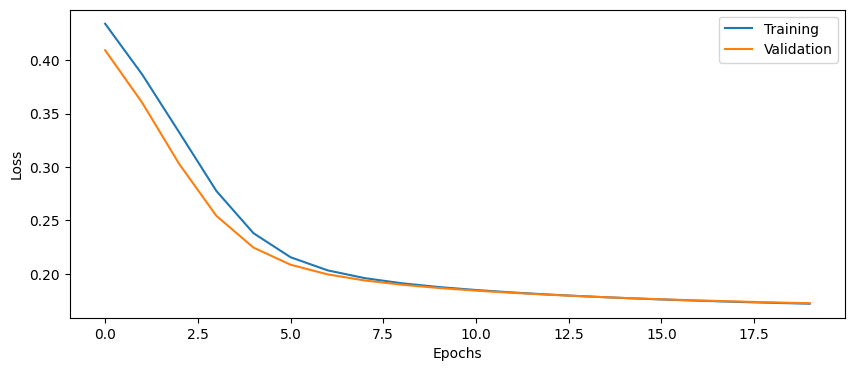

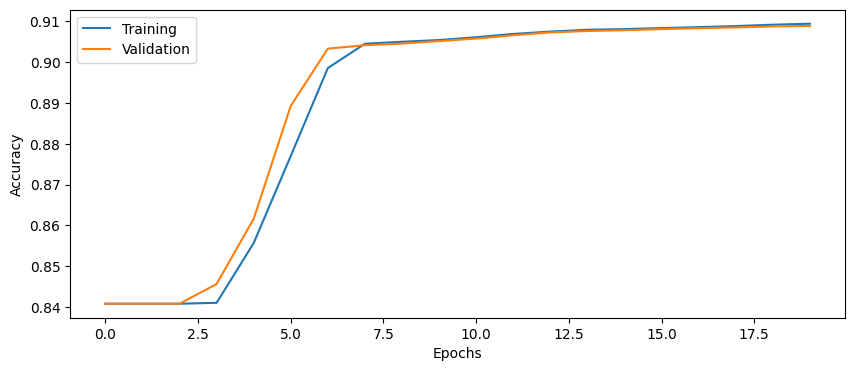

In [11]:
from utilities import plot_results

# Plot the history from the training run
plot_results(history1)

#### **<span style="color:red">Questions</span>**

3. What happens if you add several Dense layers without specifying the activation function?

4. How are the weights in each dense layer initialized as default? How are the bias weights initialized?

#### **<span style="color:green">Answers</span>**
**3.** A Dense layer with no activation specified uses activation=None, which is
the identity function. Stacking several of them just composes linear maps, and a
composition of linear maps is itself linear: X·W1·W2·W3 can always be rewritten as X·W for
a single matrix W. So the network would have no more expressive power than one Dense
layer, no matter how many you add - the extra parameters buy nothing. The nonlinear
activation is what makes depth worth anything.

**4.** By default Keras Dense layers use kernel_initializer='glorot_uniform', which is
Xavier uniform: the weights are drawn uniformly from ±sqrt(6 / (fan_in + fan_out)). This
scales the spread by the layer size so that the signal variance stays roughly constant
through the network and the units do not start saturated.

The biases use bias_initializer='zeros'. Biases can safely start at zero because the
random weights already break the symmetry between units and weights must not
be identical.


### **2.2 Adressing class imbalance**

This dataset is rather unbalanced with the majority of the samples belonging to class=1. We need to define class weights so that the training pays more attention to the class with fewer samples. We use the [`compute_class_weight`](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html) function from `scikit-learn`.

You need to call the function something like this
```python
class_weights = class_weight.compute_class_weight(class_weight = , classes = , y = )
```

otherwise it will through an error.

In [12]:
from sklearn.utils import class_weight

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Calculate class weights
value1, value2 = class_weight.compute_class_weight(class_weight='balanced',
                                                   classes=np.unique(Ytrain),
                                                   y=Ytrain)

# Print the class weights
print(f'Weight for class 0 (benign):    {value1:.4f}')
print(f'Weight for class 1 (malicious): {value2:.4f}')

# ============================================

# Convert class weights into a dictionary that can be used as input to the model.fit() function

class_weights = {0: value1,
                1: value2}


Weight for class 0 (benign):    3.1415
Weight for class 1 (malicious): 0.5946


### Train a model using class weights. 2 hidden layers with 20 nodes each


In [13]:
# Setup some training and hyper-parameters
batch_size = 10000
epochs = 20

# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Specify the learning rate, the input shape and the loss function
learning_rate = 0.1
input_shape = (Xtrain.shape[1],)
loss = BinaryCrossentropy()

# Build the model
model2 = build_DNN(input_shape, 2, 20, loss,
                   act_fun='sigmoid', optimizer='sgd', learning_rate=learning_rate)

# Train the model, provide training data and validation data
history2 = model2.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      class_weight=class_weights,
                      verbose=1)
# ============================================

Epoch 1/20
54/54 [==============================] - 2s 15ms/step - loss: 0.6691 - accuracy: 0.7852 - val_loss: 0.6271 - val_accuracy: 0.8733
Epoch 2/20
54/54 [==============================] - 1s 10ms/step - loss: 0.5747 - accuracy: 0.8762 - val_loss: 0.4992 - val_accuracy: 0.8768
Epoch 3/20
54/54 [==============================] - 1s 10ms/step - loss: 0.4224 - accuracy: 0.8776 - val_loss: 0.3654 - val_accuracy: 0.8773
Epoch 4/20
54/54 [==============================] - 1s 11ms/step - loss: 0.3047 - accuracy: 0.8781 - val_loss: 0.3032 - val_accuracy: 0.8777
Epoch 5/20
54/54 [==============================] - 1s 10ms/step - loss: 0.2539 - accuracy: 0.8786 - val_loss: 0.2835 - val_accuracy: 0.8779
Epoch 6/20
54/54 [==============================] - 1s 10ms/step - loss: 0.2327 - accuracy: 0.8791 - val_loss: 0.2711 - val_accuracy: 0.8789
Epoch 7/20
54/54 [==============================] - 1s 10ms/step - loss: 0.2218 - accuracy: 0.8806 - val_loss: 0.2652 - val_accuracy: 0.8807
Epoch 8/20
54

 1/54 [..............................] - ETA: 23s - loss: 0.7036 - accuracy: 0.1635

 9/54 [====>.........................] - ETA: 0s - loss: 0.6874 - accuracy: 0.2499 

16/54 [=======>......................] - ETA: 0s - loss: 0.6836 - accuracy: 0.5205

23/54 [===========>..................] - ETA: 0s - loss: 0.6807 - accuracy: 0.6308

30/54 [===============>..............] - ETA: 0s - loss: 0.6767 - accuracy: 0.6907

... (170 outputs left out)

35/54 [==================>...........] - ETA: 0s - loss: 0.1869 - accuracy: 0.9034

44/54 [=======================>......] - ETA: 0s - loss: 0.1867 - accuracy: 0.9035

53/54 [============================>.] - ETA: 0s - loss: 0.1863 - accuracy: 0.9037

54/54 [==============================] - 0s 7ms/step - loss: 0.1863 - accuracy: 0.9037 - val_loss: 0.2350 - val_accuracy: 0.9037


In [14]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------
# Evaluate model on test data
score = model2.evaluate(Xtest, Ytest, verbose=0)

# ============================================
print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

Test loss: 0.2318
Test accuracy: 0.9019


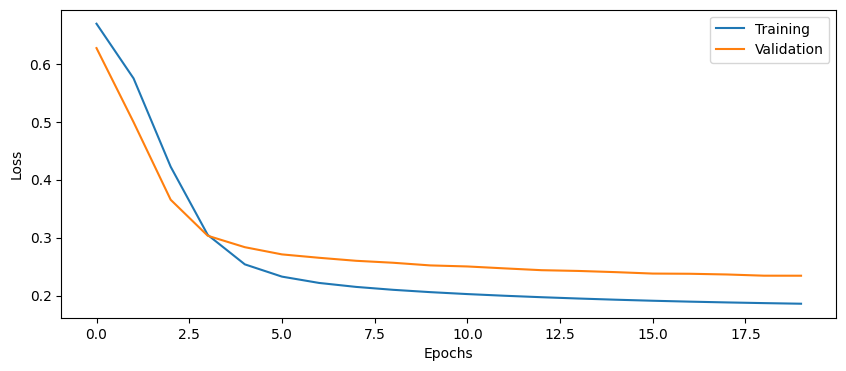

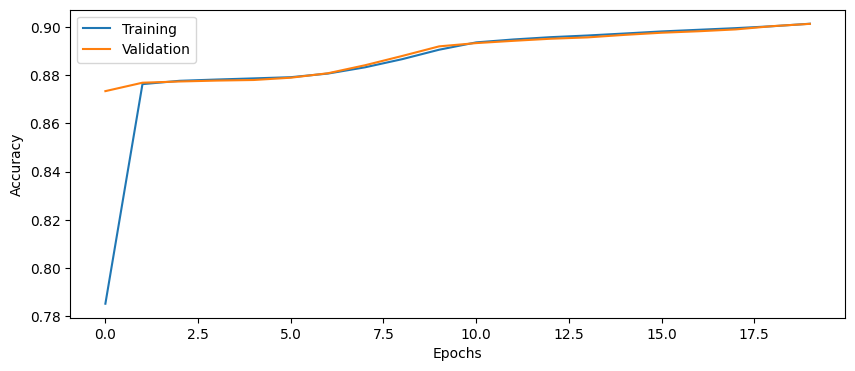

In [15]:
plot_results(history2)

In [16]:
import time
for bs in [100, 1000, 10000]:
    m = build_DNN(input_shape, 2, 20, BinaryCrossentropy(), act_fun='sigmoid',
                  optimizer='sgd', learning_rate=0.1)
    t = time.time()
    m.fit(Xtrain, Ytrain, batch_size=bs, epochs=1, verbose=0)
    print(f'batch_size={bs}: {time.time()-t:.1f} s per epoch')

batch_size=100: 24.7 s per epoch
batch_size=1000: 3.4 s per epoch
batch_size=10000: 1.2 s per epoch


### **Additional questions**
#### **<span style="color:red">Questions</span>**

5. Why do we have to use a batch size? Why can't we simply use all data at once? This is more relevant for even larger datasets.

6. What is the processing time for one training epoch when the batch size is 100? What is the processing time for one epoch when the batch size is 1,000? What is the processing time for one epoch when the batch size is 10,000? Explain the results. 

7. How many times are the weights in the DNN updated in each training epoch if the batch size is 100? How many times are the weights in the DNN updated in each training epoch if the batch size is 1,000? How many times are the weights in the DNN updated in each training epoch if the batch size is 10,000?  

8. What limits how large the batch size can be?

9.  Generally speaking, how is the learning rate related to the batch size? If the batch size is decreased, how should the learning rate be changed?
10. How many trainable parameters does the network with 4 dense layers with 50 nodes each have, compared to the initial network with 2 layers and 20 nodes per layer? Hint: use model.summary()
   
#### **<span style="color:green">Answers</span>**
**5.** Memory is the main reason. A full-batch step requires holding the activations for
all 534895 training examples at once, which does not fit in GPU memory for any reasonably
sized network, and gets worse as datasets grow. There is also a learning reason: full-batch
gradient descent makes one weight update per epoch, so 20 epochs would give only 20
updates. With batch_size=10000 the same 20 epochs give 1080 updates. The noise in the
mini-batch gradient is also useful, since it helps the optimizer escape sharp minima.

**6.** Measured on the same 2x20 network, one epoch each:
- batch size 100: 24.7 s
- batch size 1000: 3.4 s
- batch size 10000: 1.2 s

The time drops sharply as the batch size grows, even though every run does exactly the same
amount of arithmetic, all 534895 examples pass through the network once either way.

The difference is overhead per update. At batch size 100 there are 5349 separate updates in
one epoch, and each one carries a fixed cost that has nothing to do with the batch size.
With only 100 examples per step the matrices are far too small to keep the GPU busy, so most
of the time is spent on that overhead rather than on the multiplications. At batch size
10000 there are only 54 updates, so the same overhead is paid 99 times less often and each
matrix multiplication is large enough for the hardware to parallelize properly.

The gains shrink as the batch grows: going from 100 to 1000 saves 21.3 s, but going from
1000 to 10000 only saves another 2.2 s.

Note this is speed per epoch, not per unit of learning. The batch size 100 run made 5349
weight updates in its 24.7 s while the batch size 10000 run made 54 in 1.2 s, so the slow
run also learned far more in that epoch. Faster epochs do not automatically mean faster
convergence.

**7.** The training set has 534895 examples, and one update happens per batch:
- batch size 100: ceil(534895/100) = 5349 updates per epoch
- batch size 1000: ceil(534895/1000) = 535 updates per epoch
- batch size 10000: ceil(534895/10000) = 54 updates per epoch

This matches the training log, which shows "54/54" per epoch at batch size 10000 and
"535/535" at batch size 1000.

**8.** Mainly the memory of the GPU or CPU, since the activations and gradients for the
whole batch have to be held at once. The model size matters too, as a deeper or wider
network uses more memory per example. There is a statistical limit as well because past a certain
size the gradient estimate is already accurate, so a larger batch costs more memory and
gives fewer updates without improving the gradient. Very large batches are often reported
to generalize slightly worse.

**9.** They should move in the same direction. A larger batch gives a less noisy gradient
estimate, so a bigger step can be taken safely, and it also gives fewer updates per epoch
which have to be individually larger to make the same progress. So if the batch size is
decreased, the learning rate should be decreased too.

**10.** The 2-layer, 20-node network has 2301 parameters:
92*20+20 = 1860, then 20*20+20 = 420, then 20*1+1 = 21.

A 4-layer, 50-node network has 12351:
92*50+50 = 4650, then three layers of 50*50+50 = 2550 each = 7650, then 50*1+1 = 51.

That is about 5.4 times more parameters. With batch normalization added after each hidden
layer it becomes 13151, since each BatchNormalization layer adds 4*50 = 200 parameters
(gamma, beta, moving mean, moving variance), of which half are non-trainable.

### **2.3 Model regularization**

In the following sections you will explore methods for model normalization, namely `BatchNormalization` and `Dropout`, and also look at the impact of ofter activation functions and optimization algorithms.
#### **2.3.1 Batch normalization**

Now add batch normalization after each hidden dense layer in `build_DNN`.

See the [documentation](https://keras.io/layers/normalization/) for information about how to call the function.

#### **<span style="color:red">Questions</span>**
11. Why is batch normalization important when training deep networks?

#### **<span style="color:green">Answers</span>**
**11.** Batch normalization standardizes the input to each layer to roughly zero mean and
unit variance using the statistics of the current mini-batch, then rescales it with two
learned parameters. This matters for deep networks because the distribution of each layer's
input keeps shifting as the layers below it update, so every layer is chasing a moving
target. Normalizing keeps that distribution stable.

It is especially useful with sigmoid activations, which saturate and give almost zero
gradient when their input is large in magnitude. Keeping the input near zero keeps the
units in the responsive part of the curve, so gradients still reach the early layers. It
also allows a larger learning rate without diverging, and acts as a mild regularizer
because the batch statistics add a little noise.

In this lab with the same 2x20 setup and class weights, adding batch
normalization raised test accuracy from 0.9019 to 0.9158.The validation curve is noticeably
noisier though (val_loss jumps between 0.19 and 0.24 in the last epochs), because the batch
statistics differ from the running averages used at evaluation time.

### 2 hidden layers, 20 nodes each, class weights and batch normalization

Epoch 1/20
54/54 [==============================] - 2s 13ms/step - loss: 0.2957 - accuracy: 0.8742 - val_loss: 0.3787 - val_accuracy: 0.8408
Epoch 2/20
54/54 [==============================] - 1s 10ms/step - loss: 0.2114 - accuracy: 0.9037 - val_loss: 0.3500 - val_accuracy: 0.8408
Epoch 3/20
54/54 [==============================] - 1s 11ms/step - loss: 0.1929 - accuracy: 0.9093 - val_loss: 0.2985 - val_accuracy: 0.8408
Epoch 4/20
54/54 [==============================] - 1s 12ms/step - loss: 0.1845 - accuracy: 0.9114 - val_loss: 0.2421 - val_accuracy: 0.8424
Epoch 5/20
54/54 [==============================] - 1s 11ms/step - loss: 0.1795 - accuracy: 0.9123 - val_loss: 0.1962 - val_accuracy: 0.8780
Epoch 6/20
54/54 [==============================] - 1s 10ms/step - loss: 0.1762 - accuracy: 0.9129 - val_loss: 0.1771 - val_accuracy: 0.9080
Epoch 7/20
54/54 [==============================] - 1s 10ms/step - loss: 0.1737 - accuracy: 0.9135 - val_loss: 0.1755 - val_accuracy: 0.9147
Epoch 8/20
54

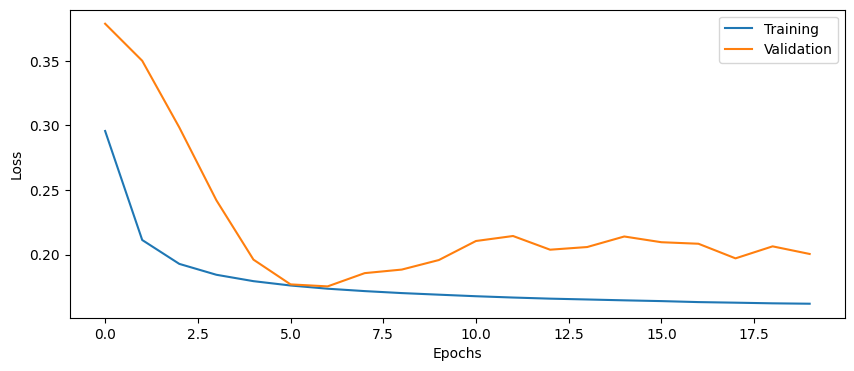

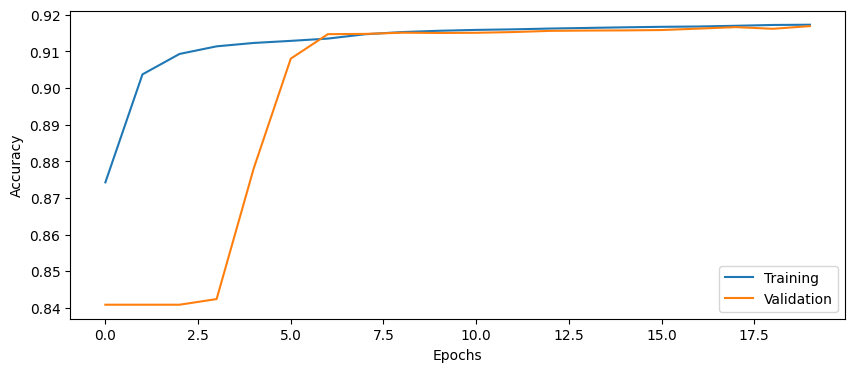

14/54 [======>.......................] - ETA: 0s - loss: 0.4311 - accuracy: 0.8099

21/54 [==========>...................] - ETA: 0s - loss: 0.3825 - accuracy: 0.8335

27/54 [==============>...............] - ETA: 0s - loss: 0.3570 - accuracy: 0.8452

32/54 [================>.............] - ETA: 0s - loss: 0.3412 - accuracy: 0.8520

38/54 [====================>.........] - ETA: 0s - loss: 0.3264 - accuracy: 0.8581

44/54 [=======================>......] - ETA: 0s - loss: 0.3149 - accuracy: 0.8623

... (210 outputs left out)

44/54 [=======================>......] - ETA: 0s - loss: 0.1635 - accuracy: 0.9164

51/54 [===========================>..] - ETA: 0s - loss: 0.1633 - accuracy: 0.9166

54/54 [==============================] - 1s 10ms/step - loss: 0.1634 - accuracy: 0.9166 - val_loss: 0.2367 - val_accuracy: 0.9153


Test loss: 0.2349
Test accuracy: 0.9158


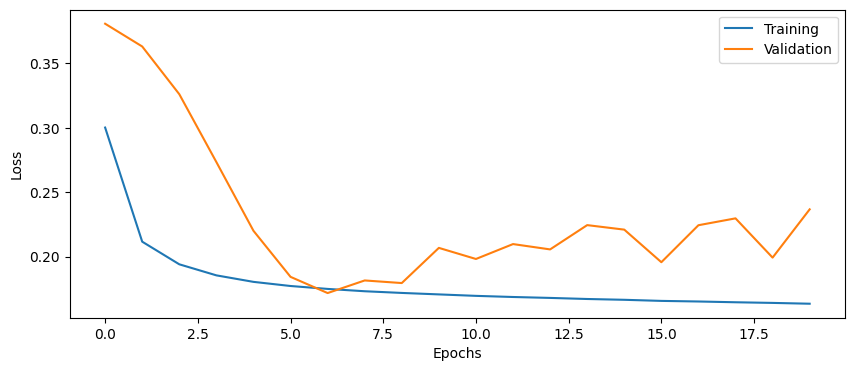

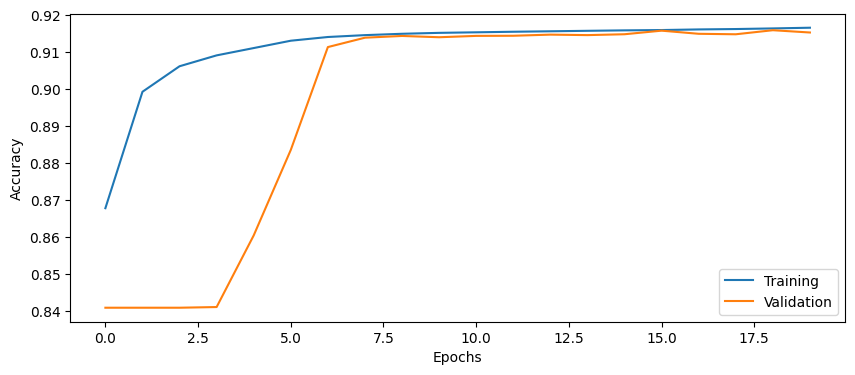

In [17]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Build and train model
model6 = build_DNN(input_shape, 2, 20, loss,
                   act_fun='sigmoid', optimizer='sgd', learning_rate=learning_rate,
                   use_bn=True)

history6 = model6.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      class_weight=class_weights,
                      verbose=1)

# Evaluate model on test data
score = model6.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history6)

#### **2.3.2 Activation function**

Try changing the activation function in each layer from sigmoid to [ReLU](https://keras.io/api/layers/activations/).

**Note**: the last layer should still have a sigmoid activation function.

### 2 hidden layers, 20 nodes each, class weights, ReLU and no batch normalization

Epoch 1/20
54/54 [==============================] - 1s 11ms/step - loss: 0.2818 - accuracy: 0.8843 - val_loss: 0.2592 - val_accuracy: 0.8912
Epoch 2/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1981 - accuracy: 0.8958 - val_loss: 0.2438 - val_accuracy: 0.8979
Epoch 3/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1875 - accuracy: 0.9006 - val_loss: 0.2386 - val_accuracy: 0.9010
Epoch 4/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1821 - accuracy: 0.9034 - val_loss: 0.2318 - val_accuracy: 0.9034
Epoch 5/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1787 - accuracy: 0.9061 - val_loss: 0.2357 - val_accuracy: 0.9059
Epoch 6/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1762 - accuracy: 0.9084 - val_loss: 0.2230 - val_accuracy: 0.9086
Epoch 7/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1743 - accuracy: 0.9097 - val_loss: 0.2285 - val_accuracy: 0.9090
Epoch 8/20
54/54 [=

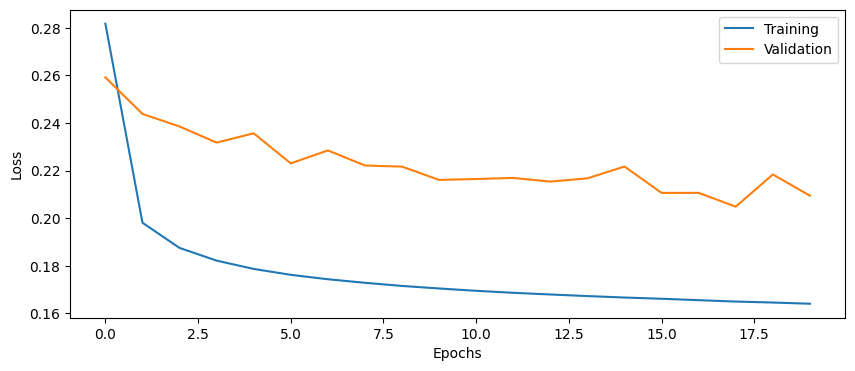

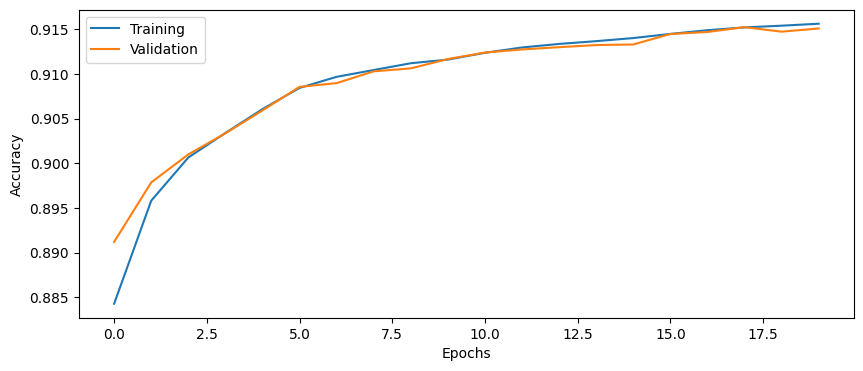

19/54 [=========>....................] - ETA: 0s - loss: 0.3858 - accuracy: 0.8642

27/54 [==============>...............] - ETA: 0s - loss: 0.3494 - accuracy: 0.8702

34/54 [=================>............] - ETA: 0s - loss: 0.3278 - accuracy: 0.8730

44/54 [=======================>......] - ETA: 0s - loss: 0.3053 - accuracy: 0.8760

52/54 [===========================>..] - ETA: 0s - loss: 0.2921 - accuracy: 0.8777

54/54 [==============================] - 1s 10ms/step - loss: 0.2899 - accuracy: 0.8780 - val_loss: 0.2737 - val_accuracy: 0.8865


... (168 outputs left out)

43/54 [======================>.......] - ETA: 0s - loss: 0.1645 - accuracy: 0.9162

51/54 [===========================>..] - ETA: 0s - loss: 0.1643 - accuracy: 0.9163

54/54 [==============================] - 0s 8ms/step - loss: 0.1644 - accuracy: 0.9163 - val_loss: 0.2142 - val_accuracy: 0.9154


Test loss: 0.2111
Test accuracy: 0.9156


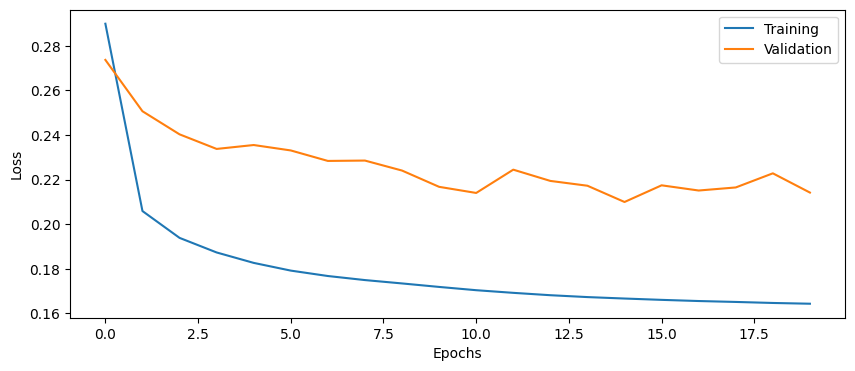

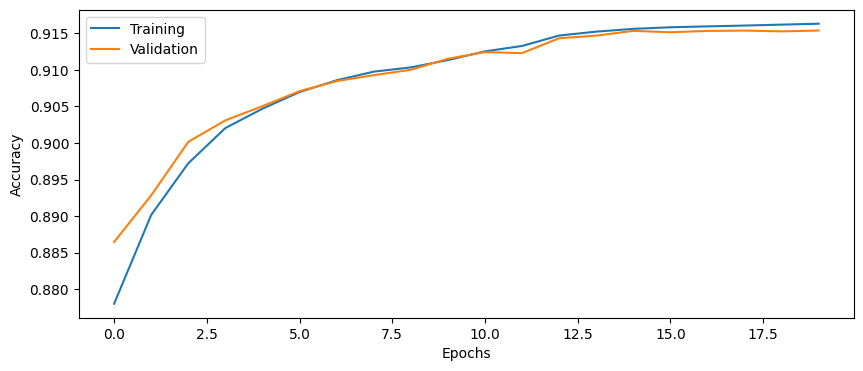

In [18]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Build and train model
model7 = build_DNN(input_shape, 2, 20, loss,
                   act_fun='relu', optimizer='sgd', learning_rate=learning_rate,
                   use_bn=False)

history7 = model7.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      class_weight=class_weights,
                      verbose=1)

# Evaluate model on test data
score = model7.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history7)

#### **2.3.3 Optimizer**

Try changing the optimizer from SGD to Adam (with learning rate 0.1 as before). Remember to import the Adam optimizer from [keras.optimizers](https://keras.io/optimizers/). 

### 2 hidden layers, 20 nodes each, class weights, Adam optimizer, no batch normalization, sigmoid activations

Epoch 1/20


2026-08-19 14:41:37.081469: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


54/54 [==============================] - 1s 12ms/step - loss: 0.2271 - accuracy: 0.8810 - val_loss: 0.2258 - val_accuracy: 0.9107
Epoch 2/20
54/54 [==============================] - 0s 8ms/step - loss: 0.1706 - accuracy: 0.9144 - val_loss: 0.2172 - val_accuracy: 0.9161
Epoch 3/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1653 - accuracy: 0.9178 - val_loss: 0.2157 - val_accuracy: 0.9176
Epoch 4/20
54/54 [==============================] - 1s 14ms/step - loss: 0.1616 - accuracy: 0.9191 - val_loss: 0.2111 - val_accuracy: 0.9179
Epoch 5/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1592 - accuracy: 0.9196 - val_loss: 0.2035 - val_accuracy: 0.9188
Epoch 6/20
54/54 [==============================] - 0s 7ms/step - loss: 0.1582 - accuracy: 0.9197 - val_loss: 0.2133 - val_accuracy: 0.9177
Epoch 7/20
54/54 [==============================] - 0s 8ms/step - loss: 0.1575 - accuracy: 0.9197 - val_loss: 0.1957 - val_accuracy: 0.9201
Epoch 8/20
54/54 [===========

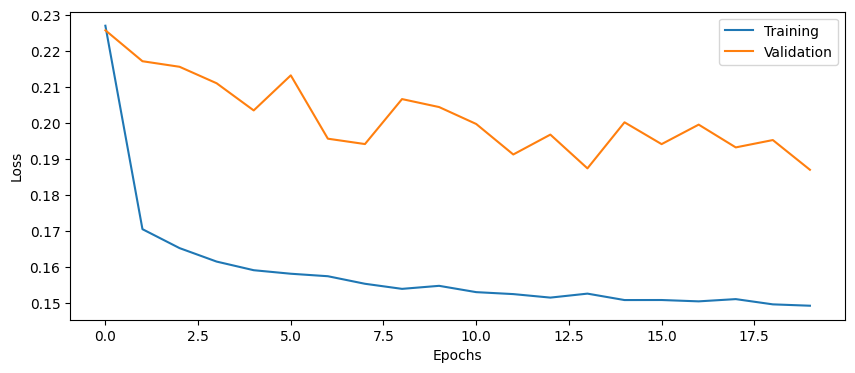

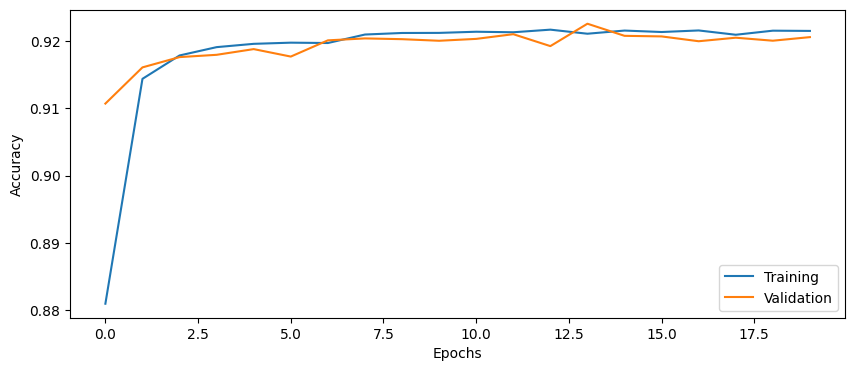

24/54 [============>.................] - ETA: 0s - loss: 0.3096 - accuracy: 0.8541

32/54 [================>.............] - ETA: 0s - loss: 0.2797 - accuracy: 0.8659

40/54 [=====================>........] - ETA: 0s - loss: 0.2592 - accuracy: 0.8750

47/54 [=========================>....] - ETA: 0s - loss: 0.2469 - accuracy: 0.8802

53/54 [============================>.] - ETA: 0s - loss: 0.2387 - accuracy: 0.8838

54/54 [==============================] - 2s 12ms/step - loss: 0.2382 - accuracy: 0.8841 - val_loss: 0.2164 - val_accuracy: 0.9136


... (180 outputs left out)

42/54 [======================>.......] - ETA: 0s - loss: 0.1513 - accuracy: 0.9208

49/54 [==========================>...] - ETA: 0s - loss: 0.1510 - accuracy: 0.9211

54/54 [==============================] - 0s 8ms/step - loss: 0.1507 - accuracy: 0.9211 - val_loss: 0.1838 - val_accuracy: 0.9208


Test loss: 0.1832
Test accuracy: 0.9211


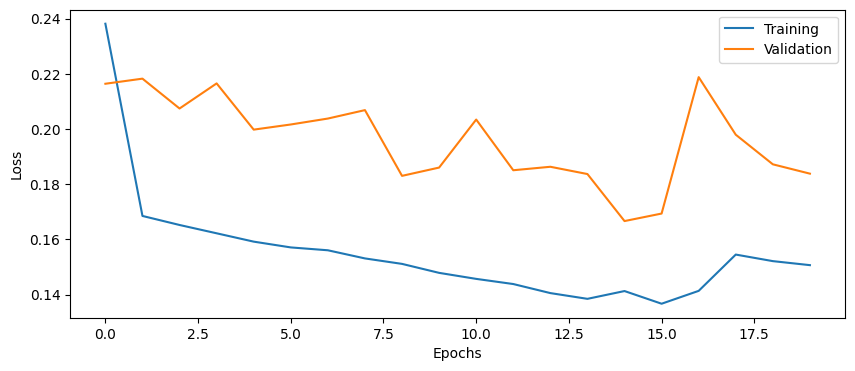

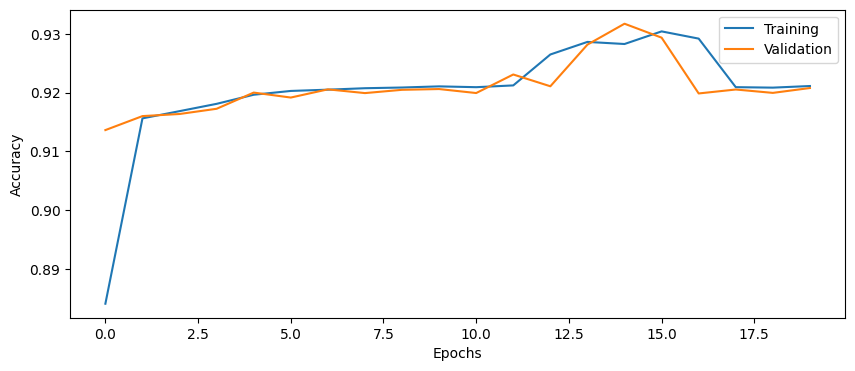

In [19]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Build and train model
model8 = build_DNN(input_shape, 2, 20, loss,
                   act_fun='sigmoid', optimizer='adam', learning_rate=learning_rate,
                   use_bn=False)

history8 = model8.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      class_weight=class_weights,
                      verbose=1)

# Evaluate model on test data
score = model8.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history8)

#### 2.3.4 **Dropout regularization**

Dropout is a type of regularization that can improve accuracy for validation and test data. It randomly removes connections to force the neural network to not rely too much on a small number of weights.

Add a Dropout layer after each Dense layer (but not after the final dense layer) in `build_DNN`, with a dropout probability of 50%. Look at the [documentation](https://keras.io/api/layers/regularization_layers/dropout/) for more information on how to call set this layer.

#### **<span style="color:red">Questions</span>**
12. How does the validation accuracy change when adding dropout?
13. How does the test accuracy change when adding dropout?

#### **<span style="color:green">Answers</span>**
**12.** It got worse. Without dropout the model reached 0.9037 validation accuracy and with
50% dropout after each hidden layer it reached 0.8894. The training curve also shows
training accuracy starting at 0.52 and climbing slowly to 0.87, far below the 0.90 it
reached without dropout.

**13.** Test accuracy dropped the same way, from 0.9019 to 0.8904.

### 2 hidden layers with 20 nodes each, class weights, dropout, SGD optimizer, no batch normalization and sigmoid activations

Epoch 1/20
54/54 [==============================] - 2s 12ms/step - loss: 0.7394 - accuracy: 0.4773 - val_loss: 0.6465 - val_accuracy: 0.8828
Epoch 2/20
54/54 [==============================] - 0s 9ms/step - loss: 0.6521 - accuracy: 0.6027 - val_loss: 0.5740 - val_accuracy: 0.8826
Epoch 3/20
54/54 [==============================] - 0s 9ms/step - loss: 0.5803 - accuracy: 0.6938 - val_loss: 0.4772 - val_accuracy: 0.8811
Epoch 4/20
54/54 [==============================] - 0s 8ms/step - loss: 0.5024 - accuracy: 0.7601 - val_loss: 0.3864 - val_accuracy: 0.8797
Epoch 5/20
54/54 [==============================] - 0s 8ms/step - loss: 0.4375 - accuracy: 0.8014 - val_loss: 0.3335 - val_accuracy: 0.8796
Epoch 6/20
54/54 [==============================] - 0s 8ms/step - loss: 0.3921 - accuracy: 0.8268 - val_loss: 0.3060 - val_accuracy: 0.8795
Epoch 7/20
54/54 [==============================] - 0s 8ms/step - loss: 0.3630 - accuracy: 0.8405 - val_loss: 0.2928 - val_accuracy: 0.8795
Epoch 8/20
54/54 [=

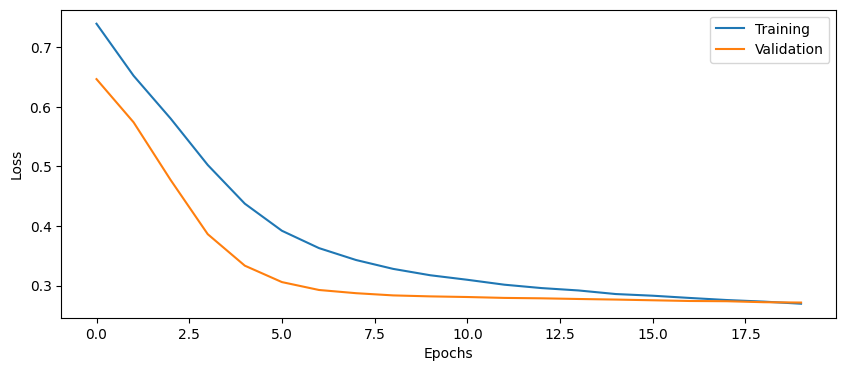

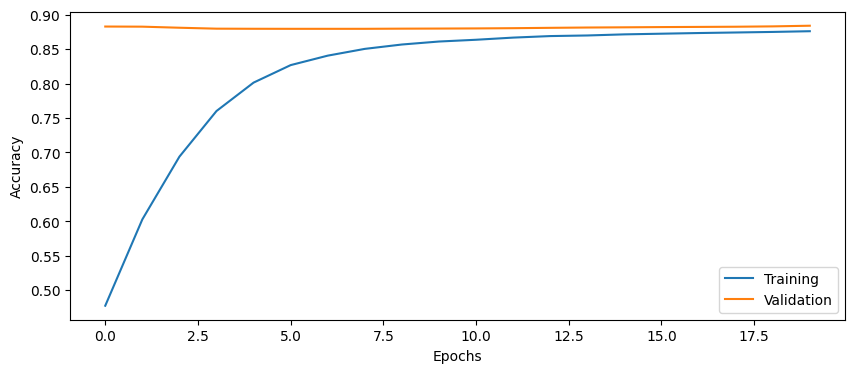

17/54 [========>.....................] - ETA: 0s - loss: 0.7683 - accuracy: 0.4378

24/54 [============>.................] - ETA: 0s - loss: 0.7569 - accuracy: 0.4632

32/54 [================>.............] - ETA: 0s - loss: 0.7441 - accuracy: 0.4846

41/54 [=====================>........] - ETA: 0s - loss: 0.7341 - accuracy: 0.5023

50/54 [==========================>...] - ETA: 0s - loss: 0.7253 - accuracy: 0.5162

54/54 [==============================] - 1s 11ms/step - loss: 0.7220 - accuracy: 0.5214 - val_loss: 0.6111 - val_accuracy: 0.8853


... (172 outputs left out)

44/54 [=======================>......] - ETA: 0s - loss: 0.2718 - accuracy: 0.8731

51/54 [===========================>..] - ETA: 0s - loss: 0.2717 - accuracy: 0.8730

54/54 [==============================] - 0s 8ms/step - loss: 0.2716 - accuracy: 0.8732 - val_loss: 0.2618 - val_accuracy: 0.8894


Test loss: 0.2589
Test accuracy: 0.8904


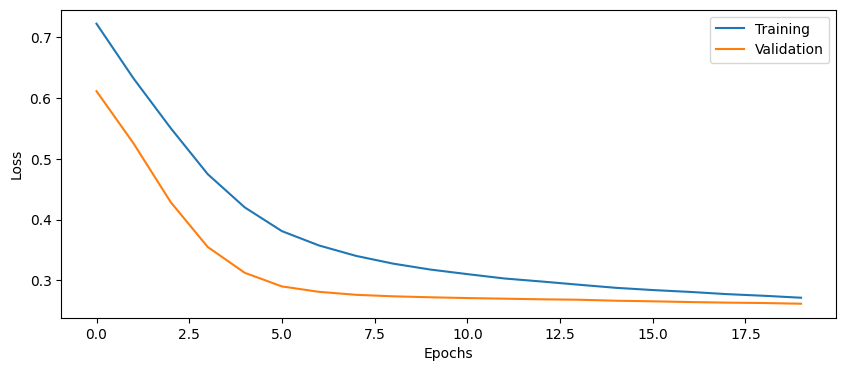

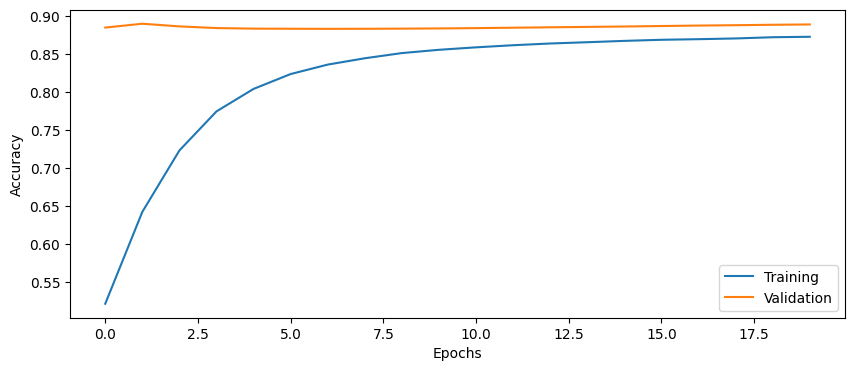

In [20]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Build and train model
model9 = build_DNN(input_shape, 2, 20, loss,
                   act_fun='sigmoid', optimizer='sgd', learning_rate=learning_rate,
                   use_bn=False, use_dropout=True)

history9 = model9.fit(Xtrain, Ytrain,
                      batch_size=batch_size,
                      epochs=epochs,
                      validation_data=(Xval, Yval),
                      class_weight=class_weights,
                      verbose=1)

# Evaluate model on test data
score = model9.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % score[0])
print('Test accuracy: %.4f' % score[1])

# Plot the history from the training run
plot_results(history9)

# Part 3:  Hyper parameter tuning

### **3.1 Manual hyper parameter tuning**
Spend some time (20 to 30 minutes) tuning the network architecture (number of layers, number of nodes per layer, activation function) and other hyper parameters (optimizer, learning rate, batch size, number of epochs, degree of regularization). For example, try a much deeper network. How much does the training time increase for a network with 10 layers?

#### **<span style="color:red">Question</span>**
14. How high classification accuracy can you achieve for the test data? What is your best configuration?
   
#### **<span style="color:green">Answers</span>**
The best test accuracy I reached with manual tuning was 0.9279, using:
- 4 hidden layers with 50 nodes each
- ReLU activations (sigmoid output)
- Adam optimizer with learning rate 0.001
- batch normalization on
- dropout off
- batch size 1000, 30 epochs, with class weights

Each change was tested separately against the 2x20 baseline first. Batch normalization took
test accuracy from 0.9019 to 0.9158, ReLU alone gave 0.9156, and Adam alone gave 0.9211, so
all three helped and combining them plus more capacity got to 0.9279.

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_30 (Dense)            (None, 50)                4650      
                                                                 
 batch_normalization_2 (Bat  (None, 50)                200       
 chNormalization)                                                
                                                                 
 dense_31 (Dense)            (None, 50)                2550      
                                                                 
 batch_normalization_3 (Bat  (None, 50)                200       
 chNormalization)                                                
                                                                 
 dense_32 (Dense)            (None, 50)                2550      
                                                                 
 batch_normalization_4 (Bat  (None, 50)              

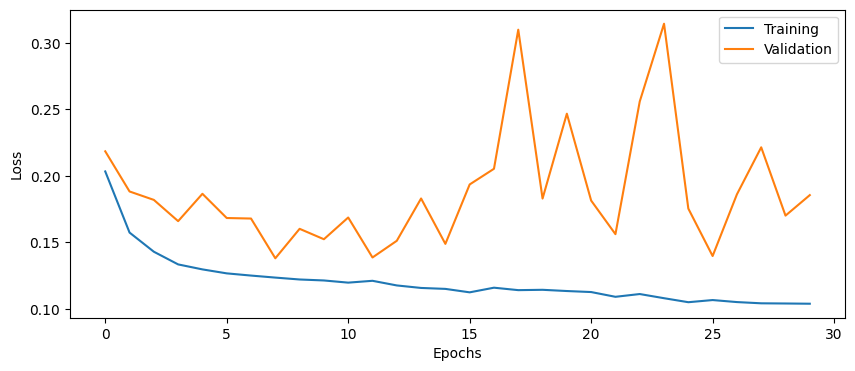

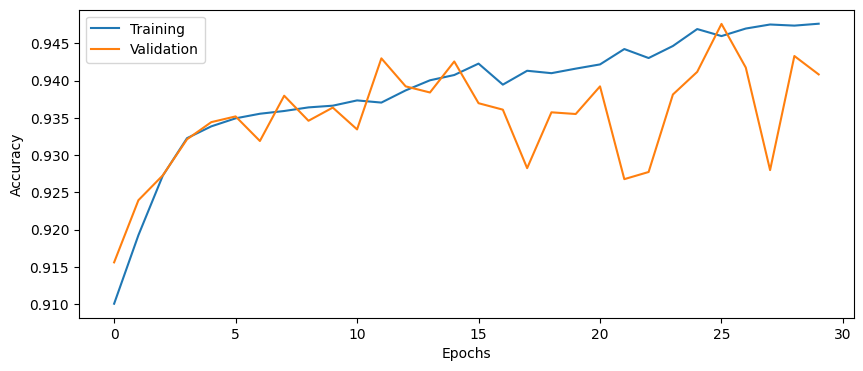

 dense_21 (Dense)            (None, 50)                4650      


 batch_normalization_2 (Bat  (None, 50)                200       


 chNormalization)                                                


 dense_22 (Dense)            (None, 50)                2550      


 batch_normalization_3 (Bat  (None, 50)                200       


 chNormalization)                                                


... (3,660 outputs left out)

526/535 [============================>.] - ETA: 0s - loss: 0.1056 - accuracy: 0.9465

531/535 [============================>.] - ETA: 0s - loss: 0.1057 - accuracy: 0.9464

535/535 [==============================] - 7s 13ms/step - loss: 0.1057 - accuracy: 0.9464 - val_loss: 0.3430 - val_accuracy: 0.9281


Test loss: 0.3406
Test accuracy: 0.9279


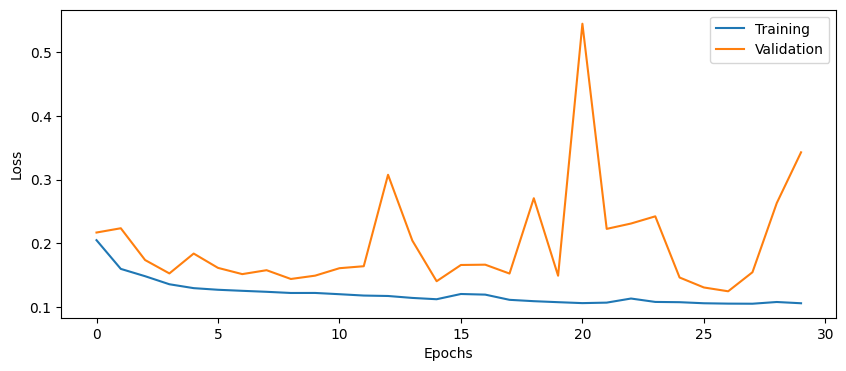

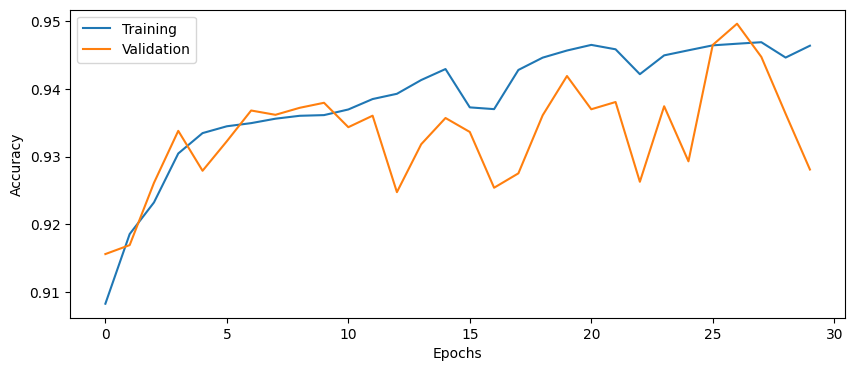

In [21]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

best_batch_size = 1000
best_epochs = 30

# Build and train model
best_model = build_DNN(input_shape, 4, 50, loss,
                       act_fun='relu', optimizer='adam', learning_rate=0.001,
                       use_bn=True, use_dropout=False, print_summary=True)

best_history = best_model.fit(Xtrain, Ytrain,
                              batch_size=best_batch_size,
                              epochs=best_epochs,
                              validation_data=(Xval, Yval),
                              class_weight=class_weights,
                              verbose=1)
# Evaluate model on test data
best_score = best_model.evaluate(Xtest, Ytest, verbose=0)

# ============================================

print('Test loss: %.4f' % best_score[0])
print('Test accuracy: %.4f' % best_score[1])

# Plot the history from the training run
plot_results(best_history)


### **3.2 Automatic hyper parameter search**
The number of hyper parameters that can be tried manually is limited and the process of trying out the different combinations and keeping track of them is time consuming and tedious. Today, there are several libraries available for automatic hyper parameter tuning (see an extensive list [here](https://github.com/balavenkatesh3322/hyperparameter_tuning)). The library that we will use in this lab is `Ray Tune` which can be integrated with many of the deep learning APIs available today (for the full description of the library capabilities see the [documentation](https://docs.ray.io/en/latest/tune/index.html)).


To use the `Ray Tune` functionality we need a function that defines the model training. This will then be used in a wrapper function that defines the hyper parameter search space, the resources available for running the search and the search algorithm. 

Start by implementing the `train_DNN` function in the `utilities.py` file (more detailed instructions are available in `utilities.py`). In the cell below, you can set up the search space and a `tune` ray object that takes the `train_DNN`. The tuner will set `train_DNN`, will select a set of hyper parameters and train several models for us (more information [here](https://docs.ray.io/en/latest/tune/key-concepts.html?_gl=1*j3ryje*_up*MQ..*_ga*NzQyMjIzNzg4LjE3MzY0MTk5MzY.*_ga_0LCWHW1N3S*MTczNjQxOTkzNS4xLjAuMTczNjQxOTkzNS4wLjAuMA..#tune-60-seconds)). 


`Ray Tune` library provides several types of hyper parameter search algorithms, including random and grid search, and Bayesian optimization. In this lab we will be using the default Ray Tune opitmization algorithm which is random serach. More infromation about the available search arlgorithms can be found [here](https://docs.ray.io/en/latest/tune/api/suggestion.html).

#### **<span style="color:red">Question</span>**
15. Run the automatic hyper parameter search with range of possible hyper parameter values as in your manual search. Does the automatic search set of parameters match those that you have found?
16. What are the benefits and drawbacks of automatic hyper parameter search?
   
#### **<span style="color:green">Answers</span>**
**15.** Largely yes. The automatic search with 10 samples chose ReLU activations, the Adam
optimizer, batch normalization on, and 4 hidden layers - all four matching what I picked
manually. The only difference is width: it chose 100 nodes per layer where I used 50.

The results are close. The search reported 0.9265 validation accuracy and my manual model
reached 0.9279 on test. So the extra width did not buy anything measurable, which suggests
the architecture choices (ReLU, Adam, batch norm, depth 4) matter far more than the exact
number of units on this dataset.

**16.** Benefits: it removes the tedious manual bookkeeping and searches combinations a
person would not think to try, it explores many configurations in parallel, the scheduler
can stop unpromising runs early rather than training all of them fully, and the process is
reproducible and documented instead of relying on intuition.

Drawbacks: it is expensive, since the whole search here took 224 seconds for only 10
samples and the cost grows with each hyperparameter added. Random search does not learn
from earlier trials unless a smarter algorithm is used. The results depend heavily on the
search space you define, so a poorly chosen range hides the good configurations, and you
still need domain knowledge to set it.

In [22]:
# import train_DNN
from utilities import train_DNN

# imports for hyperparameter tuning
from ray import tune, train
from ray.tune.schedulers import AsyncHyperBandScheduler

# --------------------------------------------  
# === Your code here =========================
# --------------------------------------------

# Define the hyper parameter, both those that should be searched and those that are fixed.
#  Hyperparameters to search are: act_fun, optimizer, use_bn, n_hidden_layers and n_hidden_units.
# The remaining parameters can be set to fixed values (This is to reduce the search space and time).
# Add the batch size and epochs so that the train_DNN can access them.
hyperparameter_space =  {
            "act_fun": tune.choice(['sigmoid', 'relu', 'tanh']),
            "optimizer": tune.choice(['sgd', 'adam']),
            "use_bn": tune.choice([True, False]),
            "n_hidden_layers": tune.choice([2, 4, 6]),
            "n_hidden_units": tune.choice([20, 50, 100]),
            # here define the fixed parameters
            "loss": BinaryCrossentropy(), 
            "learning_rate": 0.001,
            "use_dropout": False,
            "use_custom_dropout": False,
            "use_variational_layer": False,
            "input_shape": (Xtrain.shape[1],),
        }

# specify batch and number of epochs
training_config = {
            "data": (Xtrain, Ytrain, Xval, Yval),
            "epochs": 20,
            "batch_size": 10000
        }

# specify the number of samples to take from the hyper parameter space and run. The larger the number, the longer the search time.
# Start small (e.g. 2) to test your implementation, then increase.
num_samples = 10

# ============================================


# Definition of the Scheduler. This allows for several models to be trained/stopped/re-started simultaneously 
sched = AsyncHyperBandScheduler(
    metric="mean_accuracy", mode="max",
        time_attr="training_iteration", max_t=400, grace_period=20
    )

# Setting up the tuner.
tuner = tune.Tuner(
        tune.with_resources(tune.with_parameters(train_DNN, training_config=training_config), resources={"cpu": 4, "gpu": 0}), # definition of which training function to use and the available resources. Consider adding "gpu":0 to resources if available.
        tune_config=tune.TuneConfig(
            scheduler=sched,
            num_samples=num_samples,
        ),
        run_config=train.RunConfig(
            name="DNN_hp_tuning",
            stop={"mean_accuracy": 1},
            storage_path=os.path.abspath('ray_results') # where to save the summary of the hyper parameter tuning.
        ),
        param_space=hyperparameter_space,
    )

# Run the hyper parameter search.
results = tuner.fit()

(pid=142572) 2026-08-19 14:46:16.630101: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
(pid=142572) WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
(pid=142572) E0000 00:00:1787143576.649481  142572 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
(pid=142571) E0000 00:00:1787143576.624193  142571 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
(train_DNN pid=142571) 2026-08-19 14:46:20.396053: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
(pid=143829) 2026-08-19 14:46:44.326737: E external/loca

(train_DNN pid=97481) 2026-08-17 16:34:25.452401: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


(pid=98780) 2026-08-17 16:34:49.359525: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered [repeated 4x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en/master/ray-observability/user-guides/configure-logging.html#log-deduplication for more options.)
(pid=97482) WARNING: All log messages before absl::InitializeLog() is called are written to STDERR [repeated 3x across cluster]
(pid=97482) E0000 00:00:1786977261.431716   97482 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered [repeated 3x across cluster]
(pid=97482) E0000 00:00:1786977261.438157   97482 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered [r

(pid=98780) WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
(pid=98780) E0000 00:00:1786977289.400989   98780 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
(pid=98780) E0000 00:00:1786977289.414560   98780 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
(train_DNN pid=98780) 2026-08-17 16:35:02.641326: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


(pid=99629) 2026-08-17 16:35:19.757369: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered


(pid=99629) WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
(pid=99629) E0000 00:00:1786977319.795469   99629 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
(pid=99629) E0000 00:00:1786977319.804986   99629 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


... (7 outputs left out)

(pid=101415) 2026-08-17 16:36:12.366979: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
(pid=101415) WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
(pid=101415) E0000 00:00:1786977372.398710  101415 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
(pid=101415) E0000 00:00:1786977372.409864  101415 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


(train_DNN pid=101415) 2026-08-17 16:36:23.378708: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


2026-08-17 16:38:03,584	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '<local-path>/2_DNN/ray_results/DNN_hp_tuning' in 0.1079s.


2026-08-17 16:38:03,597	INFO tune.py:1041 -- Total run time: 224.60 seconds (224.43 seconds for the tuning loop).


In [23]:
# Show the best hyper parameter configuration that was found
best_trial = results.get_best_result(metric="mean_accuracy", mode='max')
print(f"Best trial config: {best_trial.config}")
print(f"Best trial final validation loss: {best_trial.metrics['keras_info']['val_loss']:0.4f}")
print(f"Best trial final validation accuracy: {best_trial.metrics['keras_info']['val_accuracy']:0.4f}")


Best trial config: {'act_fun': 'relu', 'optimizer': 'adam', 'use_bn': True, 'n_hidden_layers': 4, 'n_hidden_units': 100, 'loss': <tf_keras.src.losses.BinaryCrossentropy object at 0x76cd7cb14770>, 'learning_rate': 0.001, 'use_dropout': False, 'use_custom_dropout': False, 'use_variational_layer': False, 'input_shape': (92,)}
Best trial final validation loss: 0.1190
Best trial final validation accuracy: 0.9391


# Part 4: Uncertainty quantification

In the next sections you will explore three methods for model uncertainty estimation:
- Monte Carlo dropout where we take advantage of the dropout layer during inference time.
- Cross validation where we train several models on different splits of data.
- Bayesian neural networks (BNN) where we modify our model definition to allow the model to learn distributions over weights and the output. 

**!Note**: through the next sections, use your best model configuration that you found through hyper parameter tuning (either manual or automatic).

### **4.1 Dropout uncertainty**

Dropout can also be used during testing, to obtain an estimate of the model uncertainty. Since dropout will randomly remove connections, the network will produce different results every time the same (test) data is put into the network. This technique is called Monte Carlo dropout. For more information, see this [paper](http://proceedings.mlr.press/v48/gal16.pdf)

To achieve this, we need to redefine the Keras Dropout. This was already done for you and it is available in `utilities.py` under `myDropout`. Adapt the `build_DNN` function to two boolean arguments, use_dropout and use_custom_dropout; add a standard Dropout layer if use_dropout is true, add a `myDropout` layer if use_custom_dropout is true.

Run the same test data through the trained network 100 times, with dropout turned on. 


In [24]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Your best training parameters
batch_size = 1000
epochs = 30
input_shape = (Xtrain.shape[1],)
loss = BinaryCrossentropy()
learning_rate = 0.001

# Build and train model
model10 = build_DNN(input_shape, 4, 50, loss,
                    act_fun='relu', optimizer='adam', learning_rate=learning_rate,
                    use_bn=True, use_dropout=False, use_custom_dropout=True)

history10 = model10.fit(Xtrain, Ytrain,
                        batch_size=batch_size,
                        epochs=epochs,
                        validation_data=(Xval, Yval),
                        class_weight=class_weights,
                        verbose=1)

# ============================================

Epoch 1/30
535/535 [==============================] - 12s 19ms/step - loss: 0.3310 - accuracy: 0.8616 - val_loss: 0.2770 - val_accuracy: 0.9044
Epoch 2/30
535/535 [==============================] - 9s 18ms/step - loss: 0.2025 - accuracy: 0.9092 - val_loss: 0.2326 - val_accuracy: 0.9120
Epoch 3/30
535/535 [==============================] - 8s 14ms/step - loss: 0.1837 - accuracy: 0.9131 - val_loss: 0.2267 - val_accuracy: 0.9135
Epoch 4/30
535/535 [==============================] - 8s 14ms/step - loss: 0.1783 - accuracy: 0.9143 - val_loss: 0.2240 - val_accuracy: 0.9146
Epoch 5/30
535/535 [==============================] - 8s 14ms/step - loss: 0.1758 - accuracy: 0.9149 - val_loss: 0.2238 - val_accuracy: 0.9143
Epoch 6/30
535/535 [==============================] - 8s 14ms/step - loss: 0.1747 - accuracy: 0.9151 - val_loss: 0.2209 - val_accuracy: 0.9142
Epoch 7/30
535/535 [==============================] - 8s 15ms/step - loss: 0.1735 - accuracy: 0.9152 - val_loss: 0.2227 - val_accuracy: 0.914

  1/535 [..............................] - ETA: 26:26 - loss: 1.1733 - accuracy: 0.5030

  5/535 [..............................] - ETA: 6s - loss: 0.9824 - accuracy: 0.5138   

  9/535 [..............................] - ETA: 8s - loss: 0.9158 - accuracy: 0.5448

 13/535 [..............................] - ETA: 7s - loss: 0.8627 - accuracy: 0.5677

 17/535 [..............................] - ETA: 7s - loss: 0.8193 - accuracy: 0.5925

... (3,842 outputs left out)

528/535 [============================>.] - ETA: 0s - loss: 0.1530 - accuracy: 0.9189

531/535 [============================>.] - ETA: 0s - loss: 0.1530 - accuracy: 0.9189

535/535 [==============================] - ETA: 0s - loss: 0.1530 - accuracy: 0.9189

535/535 [==============================] - 8s 15ms/step - loss: 0.1530 - accuracy: 0.9189 - val_loss: 0.1968 - val_accuracy: 0.9177


In [25]:
# Run this cell a few times to evalute the model on test data, 
# if you get slightly different test accuracy every time, Dropout during testing is working

# Evaluate model on test data
score = model10.evaluate(Xtest, Ytest, verbose=0)
                       
print('Test accuracy: %.4f' % score[1])

Test accuracy: 0.9179


MC dropout test accuracy over 100 runs:
  mean: 0.9178
  std:  0.0001
  min / max: 0.9175 / 0.9181


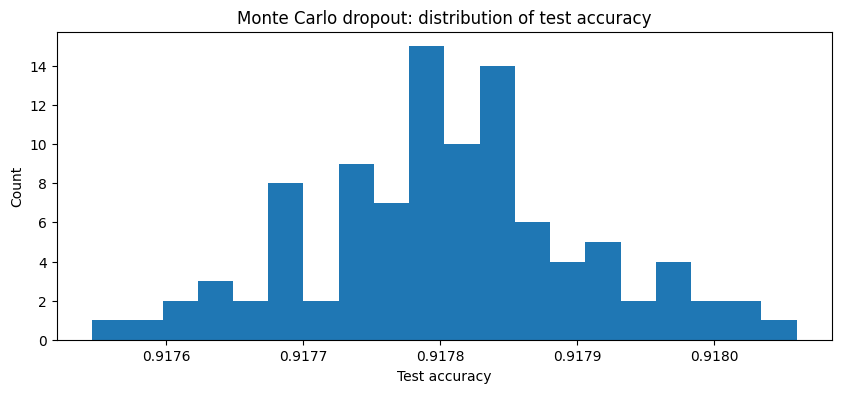

In [26]:
# ============================================
# === Your code here =========================
# ============================================
# Run the testing 100 times, and save the accuracies in an array
n_runs = 100
test_accuracies = np.zeros(n_runs)

for i in range(n_runs):
    test_accuracies[i] = model10.evaluate(Xtest, Ytest, verbose=0)[1]

# Calculate and print mean and std of accuracies
print(f'MC dropout test accuracy over {n_runs} runs:')
print(f'  mean: {test_accuracies.mean():.4f}')
print(f'  std:  {test_accuracies.std():.4f}')
print(f'  min / max: {test_accuracies.min():.4f} / {test_accuracies.max():.4f}')

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
plt.hist(test_accuracies, bins=20)
plt.xlabel('Test accuracy')
plt.ylabel('Count')
plt.title('Monte Carlo dropout: distribution of test accuracy')
plt.show()

# ============================================

### **4.2: Cross validation uncertainty**

Cross validation (CV) is often used to evaluate a model, by training and testing using different subsets of the data it is possible to get the uncertainty as the standard deviation over folds. We here use a [help function from scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html) to setup the CV. Use 10 folds with shuffling, random state 1234. 

Note: We here assume that you have found the best hyper parameters, so here the data are only split into training and testing, no validation.


In [28]:
from sklearn.model_selection import StratifiedKFold

random_state = 1234 
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Define 10-fold cross validation
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

# Define where to save the test accuracies
test_accuracies = np.zeros(n_splits)

# Loop over cross validation folds
for fold, (train_index, test_index) in enumerate(skf.split(X, Y)):
    Xtrain_cv, Xtest_cv = X[train_index], X[test_index]
    Ytrain_cv, Ytest_cv = Y[train_index], Y[test_index]
    
    # Calculate class weights for current split (remember to call the function using the input variable names e.g. class_weight='balanced', etc.)
    w0, w1 = class_weight.compute_class_weight(class_weight='balanced',
                                               classes=np.unique(Ytrain_cv),
                                               y=Ytrain_cv)
    class_weights = {0: w0, 1: w1}
    
    # Rebuild the DNN model, to not continue training on the previously trained model
    model = build_DNN(input_shape, 4, 50, loss,
                      act_fun='relu', optimizer='adam', learning_rate=0.001,
                      use_bn=True)

    # Fit the model with training set and class weights for this fold
    history = model.fit(Xtrain_cv, Ytrain_cv,
                        batch_size=1000,
                        epochs=30,
                        class_weight=class_weights,
                        verbose=0)
    
    # Evaluate the model using the test set for this fold
    score = model.evaluate(Xtest_cv, Ytest_cv, verbose=0)
    
    # Save the test accuracy in an array
    test_accuracies[fold] = score[1]
    print(f'Fold {fold+1}/{n_splits}: test accuracy {score[1]:.4f}')

# Calculate and print mean and std of accuracies
print(f'\nCross validation test accuracy over {n_splits} folds:')
print(f'  mean: {test_accuracies.mean():.4f}')
print(f'  std:  {test_accuracies.std():.4f}')

# ============================================



Fold 1/10: test accuracy 0.9359
Fold 2/10: test accuracy 0.9463
Fold 3/10: test accuracy 0.9281
Fold 4/10: test accuracy 0.9452
Fold 5/10: test accuracy 0.9299
Fold 6/10: test accuracy 0.9372
Fold 7/10: test accuracy 0.9490
Fold 8/10: test accuracy 0.9262
Fold 9/10: test accuracy 0.9252
Fold 10/10: test accuracy 0.9376

Cross validation test accuracy over 10 folds:
  mean: 0.9360
  std:  0.0082


Fold 2/10: test accuracy 0.9402


Fold 3/10: test accuracy 0.9282


Fold 4/10: test accuracy 0.9407


Fold 5/10: test accuracy 0.9363


Fold 6/10: test accuracy 0.9390


Fold 7/10: test accuracy 0.9466


Fold 8/10: test accuracy 0.9267


Fold 9/10: test accuracy 0.9273


Fold 10/10: test accuracy 0.9283

Cross validation test accuracy over 10 folds:
  mean: 0.9362
  std:  0.0078


### **4.3 Bayesian neural networks (BNN)**

Instead of mimicking Bayesian inference through MC dropout (see more details in this [paper](https://proceedings.mlr.press/v48/gal16.html)), what if we could build a model that can inherently give us a way to probe both model uncertainty (i.e. [epistemic uncertainty](https://link.springer.com/article/10.1007/s10994-021-05946-3) cause by few training samples) and data uncertainty (i.e. [aleatoric uncertainty](https://link.springer.com/article/10.1007/s10994-021-05946-3))? 

One way to achieve this is to train models to learn distributions over weights in the layers and over the output. This can be achieved by using TenssorFlow probability (see the [documentation](https://www.tensorflow.org/probability) for an in-depth description of all the functionalities). In this example we will only scratch the surface of the capabilities that a probabilistic deep learning approach has to offer, by addressing only model uncertainty. 

To start with, think about a BNN as an extension of your classical DNN, where during training instead of learning a weights for each 'connection' in the network, we ask the model to lean a distribution. After model training, during inference time, we sample from the learned distributions to obtain the weights used in the model in the forward pass. The modifications that we have to implement in our `build_DNN` function are the following:
- Substitute the hidden `Dense` layers with [`DenseVariational`](https://www.tensorflow.org/probability/api_docs/python/tfp/layers/DenseVariational) layers (this can be found under tensorflow-probability.layers). Do not forget to specify the `kl_weight` as 1/ number of iterations per epoch ([reference](https://arxiv.org/abs/1505.05424)). 
- Define the prior weights distribution (`make_prior_fn` input in the `DenseVariational`): this is the distribution that we expect the weights to have prior having seen the data. In this example we will not train the prior distribution.
- Define the posterior weights distribution (`make_posterior_fn` input in the `DenseVariational`): this is the distribution that we expect the model to learn during training. Since we do not know at priory which is the posterior distribution, we let it be very general (i.e. multivariate Gaussian distribution) which parameters are learned by the model. 

You will find the `BNN_prior` and `BNN_posterior` defined for you in the `utilities.py` file. Update the `build_DNN` to accept a new boolean input `use_variational_layer` that when true substitutes the hidden `Dense` layers with the `DenseVariational` layers. 

**!NOTE** As you will see, training the BNN model is more computationally demanding and is more prone to over-fitting. Reduce the learning rate and increase the number of epochs to address this issue.

#### **<span style="color:red">Questions</span>**
17. (MC dropout) What is the mean and the standard deviation of the test accuracy after evaluating the model on 100 times?
18. (CV) What is the mean and the standard deviation of the test accuracy?
19. (CV) What is the main advantage of dropout compared to CV for estimating test uncertainty? The difference may not be so large in this notebook, but imagine that you have a network that takes 24 hours to train.
20. (BNN) Build the BNN model and look at the number of parameters. Is there a difference between the previous DNN and the BNN? Why is that?
21. (BNN) Without training the model, evaluate the model a twice on the validation set: do you obtain the same validation accuracy? Why
22. Think of at least one advantage and one disadvantage for each of the three uncertainty estimation methods.
    

#### **<span style="color:green">Answer</span>**

**17.** Over 100 evaluations with dropout active at test time, the mean test accuracy was
0.9178 with a standard deviation of 0.0001 (min 0.9175, max 0.9181).

The standard deviation is very small. This is partly because the test set has 114621
examples, so the per-sample randomness largely averages out in the overall accuracy, and
partly because the accuracy is a hard threshold at 0.5.

**18.** Over 10 stratified folds the mean test accuracy was 0.9362 with a standard
deviation of 0.0078, with folds ranging from 0.9267 to 0.9491.

**19.** Cost. Cross validation requires training a completely new model for each fold, so
10-fold CV means 10 full training runs. For a network that takes 24 hours to train that is
10 days. MC dropout needs only one training run and then repeated forward passes, which are
cheap - so the same uncertainty estimate takes 24 hours plus minutes instead of 240 hours.

The two also measure different things, which shows in the numbers. CV's std of 0.0078 is 78
times larger than MC dropout's 0.0001, because CV captures variation from the data split and
from the random initialization of each model, while MC dropout only captures the variation
of one trained model's predictions. MC dropout is cheaper but answers a narrower question.

**20.** Yes, a very large difference. The BNN with 2 hidden layers of 20 units has 1821441
parameters, while the ordinary DNN with exactly the same architecture has 2301 - about 790
times more.

The reason is that a DenseVariational layer does not learn one number per weight, it learns
a distribution over all the weights of that layer jointly. The posterior here is a
multivariate normal parameterized by a lower-triangular Cholesky factor, so for a layer with
n weights it needs n means plus n(n+1)/2 covariance entries. The first layer has
n = 92*20 + 20 = 1860 weights, giving 1860 + 1860*1861/2 = 1732590 parameters, which is
exactly what the model summary reports. The cost grows quadratically with layer size, which
is why the BNN was kept small.

**21.** The two evaluations of the same untrained BNN gave 0.7408 and 0.7450 validation
accuracy - different results from the identical model on identical data, with no training
in between.

A DenseVariational layer stores a distribution over the weights, not the weights themselves, and draws a fresh sample from that distribution on every forward pass.
So the network that classifies the data the second time is literally not the same network as
the first time. An ordinary Dense layer holds fixed numbers and would return byte-identical
results on repeated evaluation.

The model here is untrained, so the posterior is still near its random initialization and
the samples vary a lot, which is why the two numbers differ by 0.4 percentage points and
both sit well below the naive classifier's 84%. After training, the posterior tightens and
the variability shrinks and over 100 evaluations the trained BNN gave a mean test accuracy of
0.8826 with a standard deviation of 0.0032 (0.8737 to 0.8885). That spread is still about
32 times wider than MC dropout's, because sampling whole weight matrices disturb the
network far more than dropping individual units does.

**22.** MC dropout - advantage: by far the cheapest, one training run and then arbitrarily many
cheap forward passes, and it can be added to an existing architecture with almost no
change. Disadvantage: it only measures the variability of a single trained model, so it
misses uncertainty from the data split and from initialization, which is why its std here
(0.0001) is unrealistically small compared to CV's (0.0078). It also makes the model worse
if the dropout rate is too high for the model size.

Cross validation - advantage: the most honest estimate, since each fold is a genuinely
independent train/test split, so it captures both data variability and initialization
variability, and it uses all the data for testing across folds. Disadvantage: cost, K full
training runs, which is prohibitive for large models. It also gives uncertainty about the
overall accuracy rather than about individual predictions, so it cannot tell you which
specific inputs the model is unsure about.

BNN - advantage: uncertainty is built into the model rather than approximated, it gives a
principled per-prediction distribution, and the prior offers a natural way to encode
existing knowledge and regularize. Disadvantage: hugely expensive in parameters (1821441 vs
2301 here), which forced a smaller network, and it performed worst on accuracy (0.8826 mean
against 0.9178 for MC dropout and 0.9362 for CV). It is also harder to train, needing a
lower learning rate and more epochs, and the KL weight is an extra thing to get right.

In [29]:
# --------------------------------------------
# === Your code here =========================
# --------------------------------------------

# Your best training parameters
batch_size = 1000
epochs = 50
input_shape = (Xtrain.shape[1],)
loss = BinaryCrossentropy()
learning_rate = 0.0005

n_iterations_per_epoch = int(np.ceil(Xtrain.shape[0] / batch_size))
kl_weight = 1 / n_iterations_per_epoch
print(f'Iterations per epoch: {n_iterations_per_epoch}, kl_weight = {kl_weight:.5f}')

# Build and train model
model11 = build_DNN(input_shape, 2, 20, loss,
                    act_fun='relu', optimizer='adam', learning_rate=learning_rate,
                    use_variational_layer=True, kl_weight=kl_weight,
                    print_summary=True)

history11 = model11.fit(Xtrain, Ytrain,
                        batch_size=batch_size,
                        epochs=epochs,
                        validation_data=(Xval, Yval),
                        class_weight=class_weights,
                        verbose=1)
# ============================================

Iterations per epoch: 535, kl_weight = 0.00187
Model: "sequential_27"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_variational (DenseVa  (None, 20)                1732590   
 riational)                                                      
                                                                 
 dense_variational_1 (Dense  (None, 20)                88830     
 Variational)                                                    
                                                                 
 dense_115 (Dense)           (None, 1)                 21        
                                                                 
Total params: 1821441 (6.95 MB)
Trainable params: 1821441 (6.95 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/50
535/535 [==============================] - 9s 12ms/step - loss: 4.9113 - accuracy: 0.4367

Model: "sequential_19"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense_variational (DenseVa  (None, 20)                1732590   


 riational)                                                      


... (4,715 outputs left out)

524/535 [============================>.] - ETA: 0s - loss: 0.9821 - accuracy: 0.8820

530/535 [============================>.] - ETA: 0s - loss: 0.9820 - accuracy: 0.8820

535/535 [==============================] - ETA: 0s - loss: 0.9820 - accuracy: 0.8821

535/535 [==============================] - 6s 10ms/step - loss: 0.9820 - accuracy: 0.8821 - val_loss: 0.9577 - val_accuracy: 0.8755


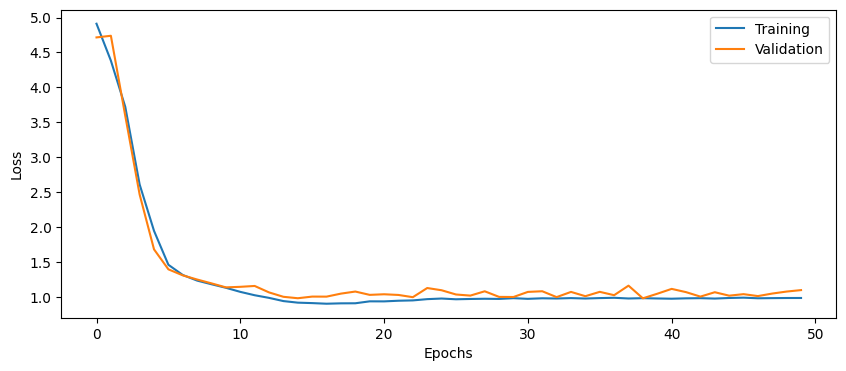

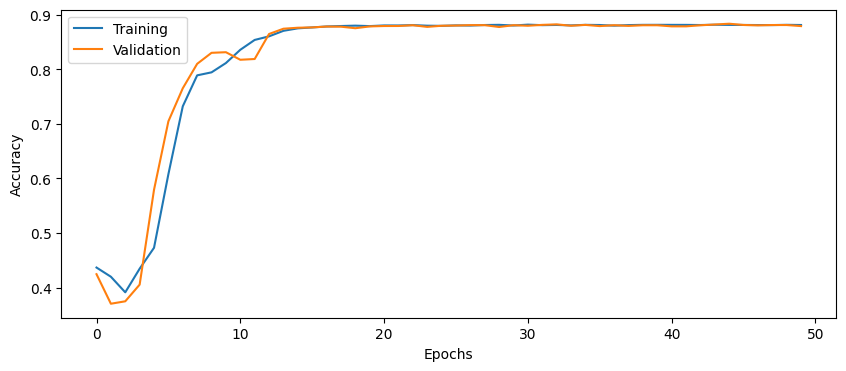

In [30]:
# Plot the history from the training run
plot_results(history11) 

In [31]:
m = build_DNN(input_shape, 2, 20, BinaryCrossentropy(), act_fun='relu',
              optimizer='adam', learning_rate=0.0005,
              use_variational_layer=True, kl_weight=kl_weight)
print('First evaluation: ', m.evaluate(Xval, Yval, verbose=0)[1])
print('Second evaluation:', m.evaluate(Xval, Yval, verbose=0)[1])

First evaluation:  0.7408328056335449
Second evaluation: 0.7450118064880371


As we have done for the MC dropout uncertainty estimation, run the evaluation on the test set 100 times and show the mean and standard deviation.

In [32]:
# ============================================
# === Your code here =========================
# ============================================
# Run the testing 100 times, and save the accuracies in an array

n_runs = 100

# Define where to save the test accuracies
test_accuracies = np.zeros(n_runs)

for i in range(n_runs):
    # predict the test set
    pred = model11.predict(Xtest, batch_size=10000, verbose=0)

    # Save predictions
    pred_labels = (pred.ravel() > 0.5).astype(int)
    test_accuracies[i] = np.mean(pred_labels == Ytest)
    
# Calculate and print mean and std of accuracies
print(f'BNN test accuracy over {n_runs} runs:')
print(f'  mean: {test_accuracies.mean():.4f}')
print(f'  std:  {test_accuracies.std():.4f}')
print(f'  min / max: {test_accuracies.min():.4f} / {test_accuracies.max():.4f}')
# ============================================

BNN test accuracy over 100 runs:
  mean: 0.8826
  std:  0.0032
  min / max: 0.8737 / 0.8885


# Part 5: DNN for regression

A similar DNN can be used for regression, instead of classification.

#### **<span style="color:red">Questions</span>**
23. How would you change the DNN used in this lab in order to use it for regression instead?

#### **<span style="color:green">Answer</span>**
Three changes, all at the output end of the network:

The final layer's activation has to change from sigmoid to linear (activation=None). A
sigmoid squashes the output into (0, 1), which is right for a probability but wrong for a
target that can take any value. If the targets are known to be non-negative, ReLU or
softplus would also work.

The loss has to change from binary cross-entropy to a regression loss - mean squared error
is the usual choice, or mean absolute error / Huber loss if the data has outliers, since
MSE punishes large errors quadratically.

The metric has to change too. Accuracy is meaningless without discrete classes, so it would
be replaced with MAE, RMSE, or R².

The number of output units stays at 1 for a single target, or becomes N for N values
predicted at once. The hidden layers, batch normalization, dropout and optimizer choices
all stay exactly as they are - only the head of the network and the loss change.

## Report

Send in this jupyter notebook, with answers to all questions.